# Step 5 — Predicting the driving style: Normal, Drowsy or Aggressive?

**Paper:** Romera, Bergasa, Arroyo, *"Need Data for Driver Behaviour Analysis? Presenting the Public UAH-DriveSet"*, IEEE ITSC 2016.

### The question
Every trip in the dataset has a **true label** in its folder name: NORMAL, DROWSY or AGGRESSIVE (the
drivers were asked to act out that style). Up to now we **never used these labels**: Steps 2–4 only
tried to match the app's *outputs*.

Now we ask: **using only our own numbers, can we tell which style each trip was?**

### The score to beat
In Step 1 we saw that the app's own guess (its highest ratio) is right for **36 of 40 trips = 90%**.

### A fair test: "leave one driver out"
We only have 6 drivers, so we test like this:
1. Learn from **5 drivers**.
2. Predict the trips of the **6th driver**, who was never seen while learning.
3. Repeat 6 times, so every driver gets to be the "new" driver once.

This way **every prediction is about a driver the method has never seen**, just like a new customer.

### Two approaches
1. **A simple rule** on two risk numbers (easy to explain, like the app).
2. **Machine learning** models that learn the pattern by themselves.

Code: `classifier.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from uah_driveset import list_trips, load_summaries
import scoring as sc
import classifier as cl

plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
ORDER = cl.LABELS

features = sc.add_weighted_events(pd.read_csv("../results/step3_trip_features.csv"))
scores = pd.read_csv("../results/step4_trip_scores.csv")
assert (features.trip_id == scores.trip_id).all()
labels, drivers = scores.behavior, scores.driver

app = load_summaries(list_trips()).set_index("trip_id").loc[scores.trip_id].reset_index()
app_pred = app[["ratio_normal", "ratio_drowsy", "ratio_aggressive"]].idxmax(axis=1).str.replace("ratio_", "").str.upper()

def accuracy(pred):
    return f"{(pred == labels).sum()}/{len(labels)} = {(pred == labels).mean():.1%}"

def confusion(pred):
    return pd.crosstab(labels, pred, rownames=["true"], colnames=["predicted"]).reindex(index=ORDER, columns=ORDER, fill_value=0)

print("App (baseline):", accuracy(app_pred))

App (baseline): 36/40 = 90.0%


## 1. Approach 1: a simple rule

From the Step 4 report card we make **two risk numbers** per trip (0 = no risk, 100 = maximum risk):

| Risk number | Made from | Meaning |
|---|---|---|
| **aggressive_risk** | points lost on accelerations, brakings, turnings, overspeeding, car-following | "how aggressive was this trip?" |
| **drowsy_risk** | points lost on weaving and drifting | "how sleepy did the driving look?" |

Example: a trip with scores 90, 80, 70, 100, 60 on the five aggressive behaviours has an average of
80, so **aggressive_risk = 100 − 80 = 20**.

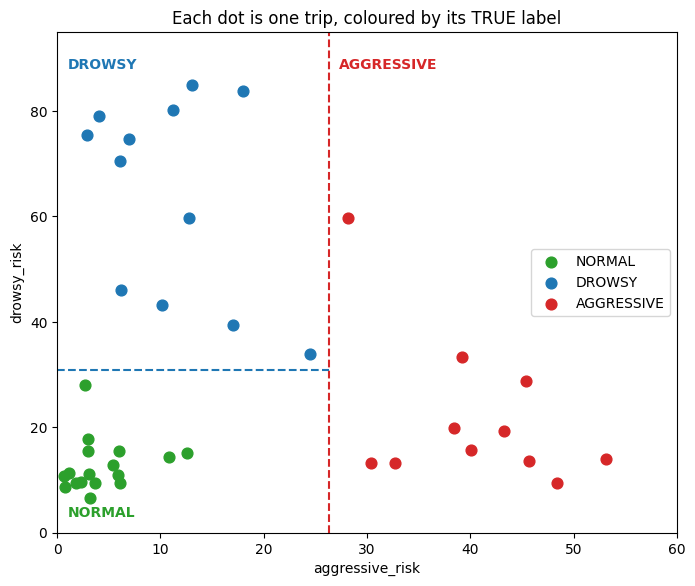

In [2]:
idx = cl.risk_indexes(scores)
fig, ax = plt.subplots(figsize=(8, 6.5))
for b in ORDER:
    m = labels == b
    ax.scatter(idx.loc[m, "aggressive_risk"], idx.loc[m, "drowsy_risk"], color=COLORS[b], s=60, label=b)
ax.axvline(cl.RULE_CUTS["aggressive_risk"], color="tab:red", ls="--")
ax.plot([0, cl.RULE_CUTS["aggressive_risk"]], [cl.RULE_CUTS["drowsy_risk"]] * 2, color="tab:blue", ls="--")
ax.text(cl.RULE_CUTS["aggressive_risk"] + 1, 88, "AGGRESSIVE", color="tab:red", weight="bold")
ax.text(1, 88, "DROWSY", color="tab:blue", weight="bold")
ax.text(1, 3, "NORMAL", color="tab:green", weight="bold")
ax.set_xlabel("aggressive_risk")
ax.set_ylabel("drowsy_risk")
ax.set_xlim(0, 60)
ax.set_ylim(0, 95)
ax.set_title("Each dot is one trip, coloured by its TRUE label")
ax.legend(loc="center right")
plt.show()

The three styles form **three separate groups**:
- 🟢 **Normal**: bottom-left (low on both)
- 🔵 **Drowsy**: top-left (high drowsy_risk, low aggressive_risk)
- 🔴 **Aggressive**: right (high aggressive_risk)

So the rule is just two questions, drawn as the dashed lines:

> 1. Is **aggressive_risk** above the red line? → **AGGRESSIVE**
> 2. Otherwise, is **drowsy_risk** above the blue line? → **DROWSY**
> 3. Otherwise → **NORMAL**

**Where do the lines go?** Halfway between the groups they separate. The red line goes halfway between
the *least aggressive* AGGRESSIVE trip and the *most aggressive* non-aggressive trip. The blue line
goes halfway between the *least drowsy* DROWSY trip and the *most drowsy* NORMAL trip.

### Fair test
For the test we learn the two lines from 5 drivers only, and predict the 6th:

In [3]:
rule_pred, cuts = cl.rule_leave_one_driver_out(idx, labels, drivers)
print("Rule:", accuracy(rule_pred))
cuts.rename_axis("left-out driver")

Rule: 39/40 = 97.5%


,aggressive_risk,drowsy_risk
left-out driver,,
D1,24.2,28.6
D2,26.3,30.9
D3,26.3,30.9
D4,26.3,30.9
D5,26.3,30.9
D6,26.3,30.9


The lines learned in each round are almost the same, so the rule is stable.

In [4]:
confusion(rule_pred)

predicted,NORMAL,DROWSY,AGGRESSIVE
true,,,
NORMAL,17,0,0
DROWSY,0,11,1
AGGRESSIVE,0,0,11


In [5]:
wrong = scores[rule_pred != labels][["trip_id", "behavior"]].assign(predicted=rule_pred[rule_pred != labels])
wrong.join(idx.round(1))

,trip_id,behavior,predicted,aggressive_risk,drowsy_risk
6,20151111135612-13km-D1-DROWSY-SECONDARY,DROWSY,AGGRESSIVE,24.5,33.8


**The only mistake:** D1's drowsy trip on the secondary road was called aggressive. Its
aggressive_risk (24.5) was just above the line learned without D1 (24.2). This is the trip from
Step 1 with the **hardest brake in the whole dataset (−0.57 g)**: a "sleepy" driver noticing late and
slamming the brakes looks aggressive to the sensors.

## 2. Approach 2: machine learning

Instead of writing the rule ourselves, we let a model **learn** the pattern from the
**7 risk numbers** (weighted harsh brakes, accelerations and turns per 10 km, weaving, drifting,
speeding and tailgating). We try three common models:

| Model | Idea in one line |
|---|---|
| **Decision tree** (2 levels) | asks 2 yes/no questions, like our rule, but chooses the questions itself |
| **Logistic regression** | gives each risk number a weight, adds them up, and picks the style with the highest total |
| **Random forest** | 300 small decision trees vote; the majority wins |

Same fair test: learn from 5 drivers, predict the 6th.

In [6]:
X = features[list(sc.BEHAVIOURS.values())]
models = {
    "Decision tree (2 levels)": DecisionTreeClassifier(max_depth=2, random_state=0),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest (300 trees)": RandomForestClassifier(n_estimators=300, random_state=0),
}
model_preds = {name: cl.model_leave_one_driver_out(m, X, labels, drivers) for name, m in models.items()}
for name, pred in model_preds.items():
    print(f"{name:28s} {accuracy(pred)}")

Decision tree (2 levels)     37/40 = 92.5%
Logistic regression          40/40 = 100.0%
Random forest (300 trees)    40/40 = 100.0%


### What did the decision tree learn?
Trained on all 40 trips, the 2-level tree asks these questions (read from the top):

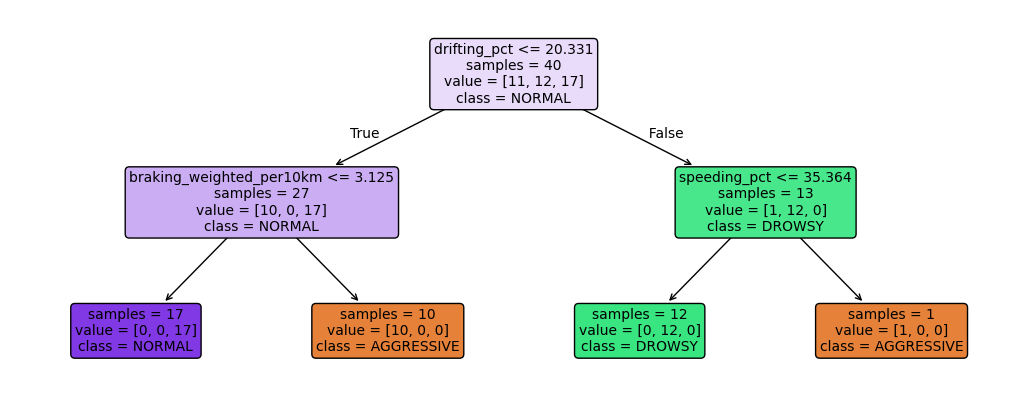

In [7]:
tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, labels)
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled=True, rounded=True,
          impurity=False, fontsize=10, ax=ax)
plt.show()

It found the same idea as our rule on its own: **drifting** separates drowsy from the rest, and
**braking / speeding** separate aggressive. Its 3 mistakes in the fair test are all aggressive trips
(2 called normal, 1 called drowsy): with only two questions it can look at just two or three risk
numbers per trip, while our rule combines all seven.

### Which risk numbers matter most?
The random forest can tell us how much each risk number helped its decisions:

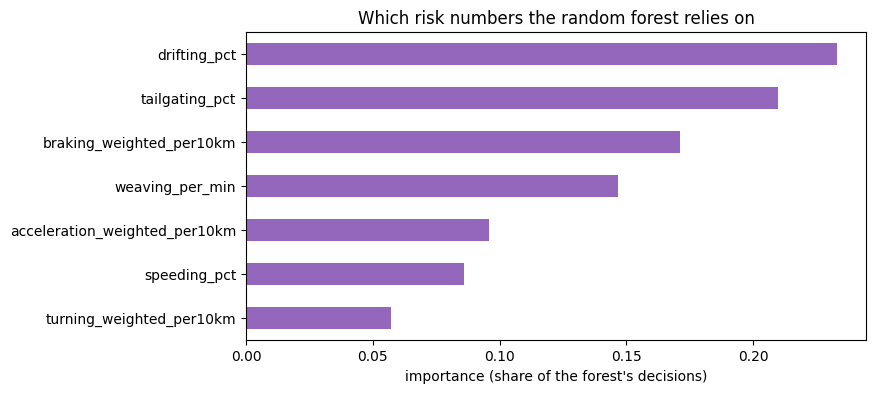

In [8]:
forest = RandomForestClassifier(n_estimators=300, random_state=0).fit(X, labels)
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
ax = importance.plot.barh(figsize=(8, 4), color="tab:purple")
ax.set_xlabel("importance (share of the forest's decisions)")
ax.set_title("Which risk numbers the random forest relies on")
plt.show()

**Drifting** (for drowsy) and **tailgating, speeding and braking** (for aggressive) matter most,
which matches what we saw in Steps 2–4.

## 3. Results: did we beat the app?

In [9]:
results = pd.DataFrame({
    "method": ["App (DriveSafe ratios)", "Our rule (2 risk numbers)"] + list(model_preds),
    "correct": [(app_pred == labels).sum(), (rule_pred == labels).sum()] + [(p == labels).sum() for p in model_preds.values()],
})
results["accuracy"] = (results.correct / len(labels) * 100).round(1).astype(str) + "%"
results.set_index("method")

,correct,accuracy
method,,
App (DriveSafe ratios),36,90.0%
Our rule (2 risk numbers),39,97.5%
Decision tree (2 levels),37,92.5%
Logistic regression,40,100.0%
Random forest (300 trees),40,100.0%


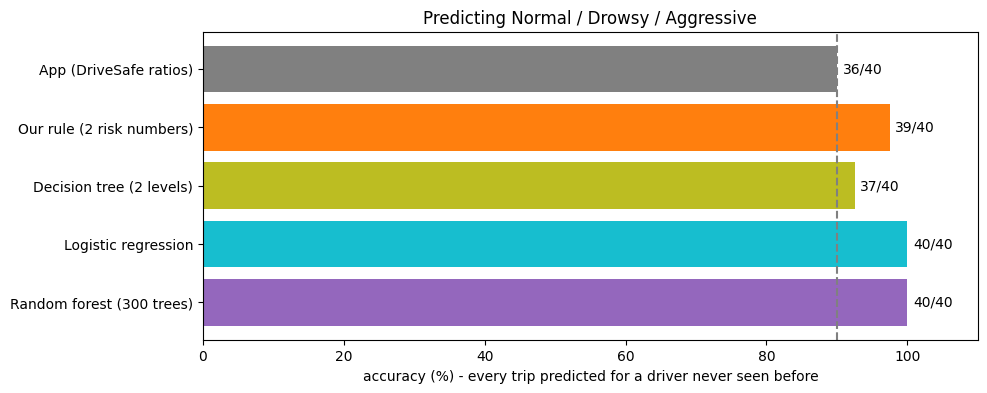

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["grey", "tab:orange", "tab:olive", "tab:cyan", "tab:purple"]
bars = ax.barh(results.method, results.correct / len(labels) * 100, color=colors)
ax.bar_label(bars, labels=[f"{c}/40" for c in results.correct], padding=4)
ax.axvline(90, color="grey", ls="--")
ax.set_xlim(0, 110)
ax.set_xlabel("accuracy (%) - every trip predicted for a driver never seen before")
ax.invert_yaxis()
ax.set_title("Predicting Normal / Drowsy / Aggressive")
plt.show()

### Confusion tables
Rows = the true style, columns = the predicted style. Numbers off the diagonal are mistakes.

In [11]:
tables = {"App": confusion(app_pred), "Our rule": confusion(rule_pred),
          "Logistic regression": confusion(model_preds["Logistic regression"])}
pd.concat(tables, axis=1)

App                   Our rule                    \
predicted  NORMAL DROWSY AGGRESSIVE   NORMAL DROWSY AGGRESSIVE   
true                                                             
NORMAL         17      0          0       17      0          0   
DROWSY          1     11          0        0     11          1   
AGGRESSIVE      3      0          8        0      0         11   

           Logistic regression                    
predicted               NORMAL DROWSY AGGRESSIVE  
true                                              
NORMAL                      17      0          0  
DROWSY                       0     12          0  
AGGRESSIVE                   0      0         11

### Which trips did the app get wrong, and did we?

In [12]:
check = scores[["trip_id", "behavior"]].assign(
    app=app_pred, our_rule=rule_pred, logistic_regression=model_preds["Logistic regression"])
check[(check.app != check.behavior) | (check.our_rule != check.behavior)]

,trip_id,behavior,app,our_rule,logistic_regression
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,AGGRESSIVE,NORMAL,AGGRESSIVE,AGGRESSIVE
6,20151111135612-13km-D1-DROWSY-SECONDARY,DROWSY,DROWSY,AGGRESSIVE,DROWSY
9,20151120135152-25km-D2-DROWSY-MOTORWAY,DROWSY,NORMAL,DROWSY,DROWSY
20,20151126134736-26km-D3-AGGRESSIVE-MOTORWAY,AGGRESSIVE,NORMAL,AGGRESSIVE,AGGRESSIVE
39,20151221120051-26km-D6-AGGRESSIVE-MOTORWAY,AGGRESSIVE,NORMAL,AGGRESSIVE,AGGRESSIVE


The app called **3 aggressive trips and 1 drowsy trip "normal"**. Our rule got all four right.
Our only mistake is a different trip (the late-braking drowsy trip above).

## 4. Be careful with these numbers ⚠️

These results are very good, but for the report it is important to be honest about what they mean:

- **Only 40 trips from 6 drivers.** One trip = 2.5%. A perfect 40/40 with such a small set does not
  mean the method would be perfect on thousands of real drivers.
- **The drivers were acting.** "Aggressive" and "drowsy" were performed on purpose, so they are probably
  more extreme and easier to tell apart than real-life behaviour.
- **Our features were not tuned on the labels**, which is good: Steps 2–4 only tried to match the
  app's outputs, and the true labels are used for the first time here, always with a driver left out.
- **The simple rule is the most convincing result.** It has only 2 numbers to learn and is easy to
  explain, yet it scores 97.5%. The machine-learning models agree with it.

## 5. Save the predictions

In [13]:
out = scores[["trip_id", "driver", "behavior", "road"]].join(idx.round(1)).assign(
    predicted_rule=rule_pred, predicted_logreg=model_preds["Logistic regression"], predicted_app=app_pred)
out.to_csv("../results/step5_predictions.csv", index=False)
out.head()

,trip_id,driver,behavior,road,aggressive_risk,drowsy_risk,predicted_rule,predicted_logreg,predicted_app
0,20151110175712-16km-D1-NORMAL1-SECONDARY,D1,NORMAL,SECONDARY,12.6,15.1,NORMAL,NORMAL,NORMAL
1,20151110180824-16km-D1-NORMAL2-SECONDARY,D1,NORMAL,SECONDARY,6.0,15.5,NORMAL,NORMAL,NORMAL
2,20151111123124-25km-D1-NORMAL-MOTORWAY,D1,NORMAL,MOTORWAY,2.7,28.0,NORMAL,NORMAL,NORMAL
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,D1,AGGRESSIVE,MOTORWAY,28.1,59.8,AGGRESSIVE,AGGRESSIVE,NORMAL
4,20151111132348-25km-D1-DROWSY-MOTORWAY,D1,DROWSY,MOTORWAY,12.7,59.8,DROWSY,DROWSY,DROWSY


## Summary

| Method (each trip predicted for an unseen driver) | Correct | Accuracy |
|---|---|---|
| App (DriveSafe ratios), the paper's baseline | 36/40 | 90.0% |
| **Our simple rule** (aggressive_risk + drowsy_risk) | **39/40** | **97.5%** |
| Decision tree (2 levels) | 37/40 | 92.5% |
| Logistic regression | 40/40 | 100% |
| Random forest | 40/40 | 100% |

**Main finding:** using only our own detectors and scores, we tell Normal, Drowsy and Aggressive
trips apart **at least as well as the original app**. Aggressive driving shows up in braking, speeding
and tailgating; drowsy driving shows up in drifting and weaving.

**Next step (Step 6):** turn this into the project's own idea, a **driver safety score** (like a
credit score for driving) that an insurance company could use.